## Optimization model - v1.0

Hi all - this is an initial model that allows for optimization of the MOSH rod arrangements before optimizing for dwell time. I think it would be an interesting inclusion for our manuscript. In this notebook I walk through the basic formalism of the model and show how it works for a simple system.

### Setup

This section sets the parameters for the model - you can skip to the next section!

In [1]:
# Allows Python to find mosh_src if this notebook is moved
import sys
sys.path.insert(0, "/Users/seanmullane/Desktop/Research_2023/modulated_shielding/")

# Add functionality to parse folders
import os

# Import matplotlib and numpy - helpful Python libraries for scientific computing
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal

from scipy import optimize

# Import all MOSH plotting functions
from mosh_src.plotting_functions import *

In [2]:
# Number of bins and dosing grid half-length - both set in TOPAS parameter files
bins_mosh = 85
dose_grid_half_mosh = 2.5 # cm

# Z coordinate of radioactive source - set in TOPAS parameter files
source_transZ_mosh = -0.5 # cm

# Applicator radius - set in TOPAS parameter files
applicator_rad = 0.3

# Computes the lattice length for the simulation space in cm
lattice_mosh = dose_grid_half_mosh*2/bins_mosh

In [3]:
# Assume dose point in center of ROI
dose_point = (0.5, 0.0)

source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9] # cm

# 0 = x, 1 = y, 2 = z
const_axis = 2

# Set the range of our contour plots
# Maximum range set by TOPAS parameter files
rngX = (-1.5, 1.5)
rngY = (-1.5, 1.5)

dose = 100 # % of dose
# Compute the plane of the source
source_plane = cm_to_voxel(np.array(source_transZ_mosh), bins_mosh, lattice_mosh)

In [4]:
# Rod positions - from TOPAS parameter file
rod_1_pos = np.array([0, 0.18]) # cm
rod_2_pos = np.array([0.156, 0.09])
rod_3_pos = np.array([0.156, -0.09])
rod_4_pos = np.array([0, -0.18])
rod_5_pos = np.array([-0.156, -0.09])
rod_6_pos = np.array([-0.156, 0.09])

# Combine for ease of use
ROD_POS = [rod_1_pos, rod_2_pos, rod_3_pos, rod_4_pos, rod_5_pos, rod_6_pos]
NUM_RODS = 6

In [5]:
## Define relevant functions ##

# Compute the gamma function
def compute_gamma(back_voxel_pos: np.array, scaling: float=1.0) -> float:
    gamma = []
    for r in ROD_POS:
        gamma.append(1/(np.linalg.norm(back_voxel_pos - r)))
    return np.array(gamma)/scaling

# Select OAR area
# Given X and Y bounds (in cm) for OAR, select appropriate voxels for objective function calculation
def select_region(x: tuple, y: tuple) -> np.ndarray:
    """
    x = (xmin, xmax)
    y = (ymin, ymax)

    Returns:
    - r x c array "oar," where r = xmax - xmin, c = ymax - ymin, and each element is a tuple (x_cm, y_cm) 
    identifying a voxel in the ROI/OAR area
    """
    # convert to voxel space to determine size of oar
    x_vox = cm_to_voxel(np.array(x), bins_mosh, lattice_mosh)
    y_vox = cm_to_voxel(np.array(y), bins_mosh, lattice_mosh)

    # construct empty oar array
    oar = np.empty((x_vox[1] - x_vox[0], y_vox[1] - y_vox[0]), dtype=tuple)

    # perform inverse voxel --> cm transformation
    x_inverse = voxel_to_cm(x_vox, bins_mosh, lattice_mosh)
    y_inverse = voxel_to_cm(y_vox, bins_mosh, lattice_mosh)
    
    x_space = np.arange(x_inverse[0], x_inverse[1], lattice_mosh)
    y_space = np.arange(y_inverse[0], y_inverse[1], lattice_mosh)

    for i in range(np.shape(x_space)[0]):
        for j in range (np.shape(y_space)[0]):
            oar[i][j] = np.array([x_space[i], y_space[j]])
    return (oar, x_vox, y_vox)

### Model definition

Here's the overall problem: given a particular region-of-interest, an organ-at-risk, and an applicator location, how do we determine an arrangement of rods that maximizes the dose at the ROI and minimizes the dose at the OAR?

This problem is difficult for two reasons. First, the rod arrangement for a given applicator is a set of discrete variables $\{ \theta_1, \theta_2, ..., \theta_6 \}$ where $\theta_j = 1$ if a rod is removed from channel $j$ and 0 otherwise. This means that our optimization problem is a function of discrete (not continuous) variables, so we have to use the formalism of discrete optimization to solve this problem. In general, it's more difficult to set up a discrete optimization algorithm than a continuous one, since in a continuous optimization problem the overall formalism is always "take the derivative or gradient of an objective function and use this to find the optimal values for the variables." In a discrete problem it's not always clear how to do this, so writing an objective function can be more difficult.

Second, it's expensive for us to run simulations. Ideally, our algorithm would work something like this: define an objective function that is a function of rod arrangement, the OAR, and the ROI; guess an initial rod arrangement; run a simulation with the initial arrangement and determine the total dose delivered to the ROI and OAR; use the objective function to determine a new rod arrangement based on the dose; and then repeat this process until the objective function is minimized and an optimal rod arrangement is found. Unfortunately, this process requires us to run a new simulation at every iteration of the algorithm. Even if we were to run relatively coarse simulations (e.g. $10^6$ histories), this would still take a significant amount of computational time since we may run hundreds or thousands of iterations for more complex problems. Thus, it would be adventageous to develop a model that does not require running a new simulation at each timestep of the optimization algorithm.

Let's start with the second issue. To avoid running a new simulation at each timestep, we need a proxy for the dose at a particular voxel given a particular rod arrangement. We can do this by recognizing that the dose at a given voxel is entirely dependent on (1) the distance of that voxel from each applicator channel and (2) whether each channel is "open" (rod removed) or "closed" (rod inserted). Of note, in this case we're neglecting any effects from variations in tissue type around the applicator. 

In other words, we want a quantity that is a function of distance from each channel and the arrangement of the channel. To start, we'll define a quantity $\gamma$ as follows:

$$\gamma_{ij} = \frac{1}{| \vec{p_i} - \vec{r_j} |}$$

where $\vec{p_i}$ is the position of the $i$th voxel and $\vec{r_j}$ is the position of the $j$th channel for $j \in \{1, 2, ..., 6\}$. As the distance $d$ between a voxel and a channel grows, this function drops off $\propto 1/d$. Since there are six total channels, for the $i$th voxel we can define the following vector:

$$\vec{\gamma_i} = [\gamma_{i1}, \gamma_{i2}, ..., \gamma_{i6}]^T$$

where $\gamma_{i,1}$ represents the quantity $\gamma_{ij}$ computed for the channel at position $j = 1$. You'll note, however, that this quantity does not take into account whether a given channel is filled or empty. To do this, we define the quantity $\vec{\theta}$ as:

$$\vec{\theta} = [\theta_1, \theta_2, ..., \theta_6]^T$$

where $\theta_j = 1$ if a rod is removed and 0 otherwise. We can now compute the following quantity:

$$\Gamma_{i} \equiv \vec{\gamma_i} \cdot \vec{\theta} = \sum_{j = 1}^{6} \gamma_{ij} \theta_j = \gamma_{i1} \theta_1 + \gamma_{i2} \theta_2 + \cdots + \gamma_{i6} \theta_6$$

Let's note a few things about the quantity $\Gamma_i$. First, it is a scalar since it's formed from the dot product of two vectors. Second, it takes into account whether a given channel is filled or empty. If channel $j$ is filled, the corresponding component $\gamma_{ij}$ from the vector $\vec{\gamma}_i$ does not contribute to the overall sum $\Gamma_i$ since $\gamma_{ij} \cdot \theta_j = 0$. For a given voxel, the quantity $\Gamma_i$ will decrease if the voxel is farther from the applicator and will decrease if a channel is filled. Of note, the amount that the quantity $\Gamma_i$ decreases when a particular channel is filled is weighted by how close the voxel is to that particular channel. For a voxel immediately adjacent to channel 3, the quantity $\Gamma_i$ will change more significantly when that channel is opened or closed than for a voxel that is far away from the entire applicator.

These properties make $\Gamma_i$ a good proxy for the dose delivered to voxel $i$. We can check this by plotting $\Gamma_i$ for each voxel with a given rod configuration.

In [6]:
# Step 1 - compute GAMMA_MAX
X = voxel_to_cm(np.arange(0, bins_mosh), bins_mosh, lattice_mosh)
Y = voxel_to_cm(np.arange(0, bins_mosh), bins_mosh, lattice_mosh)

Xv, Yv = np.meshgrid(X, Y, indexing='ij')

GAMMA_MAX = np.empty((bins_mosh, bins_mosh))
## Change this vector to adjust which channels are shielded ##
rod_config = np.array([1, 1, 1, 1, 1, 1])

for i in range(bins_mosh):
    for j in range(bins_mosh):
        if np.linalg.norm((Xv[i][j], Yv[i][j])) <= applicator_rad:
            GAMMA_MAX[i][j] = 0
        else:
            g = compute_gamma(np.array([Xv[i][j], Yv[i][j]]))
            GAMMA_MAX[i][j] = np.dot(g, rod_config)

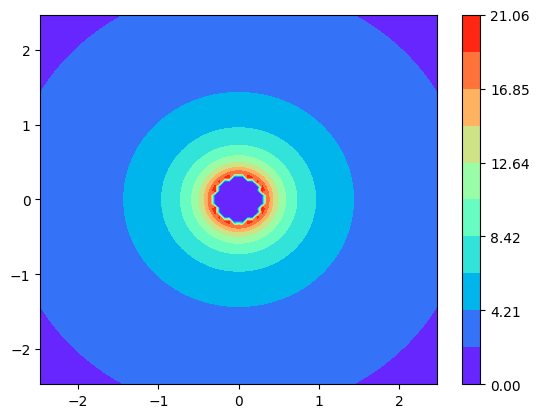

In [7]:
# Plot GAMMA_MAX as a sanity check
fig, ax = plt.subplots()

contour = ax.contourf(Xv, Yv, GAMMA_MAX, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar = fig.colorbar(contour)

In the code above, we've plotted $\Gamma_i$ for every voxel in this plane assuming all channels are empty, so $\vec{\theta} = [1, 1, ..., 1]^T$. Note that the resulting plot looks very similar to our Monte Carlo simulations with every shielding rod removed. While the scaling has changed (each voxel has a different "energy" assigned to it), the overall structure of the plot is maintained. You can check this by adjusting the parameter `rod_config` in the code block above. For example, setting `rod_config` = $[1, 0, 1, 1, 1, 1]^T$ inserts the rod at position 2 and recreates the plot accordingly. In this case you'll notice slight decrease in the "intensity" of the plot immediately adjacent to rod position 2 (roughly the 2 o'clock position), consistent with our simulations.

In [8]:
# Step 2 - define ROI and OAR
x_roi = (0.5, 1.0)
y_roi = (-0.25, 0.25)

# Note that the problem is asymmetric in this case
x_oar = (-1.5, -1.0)
y_oar = (-1.0, -0.5)

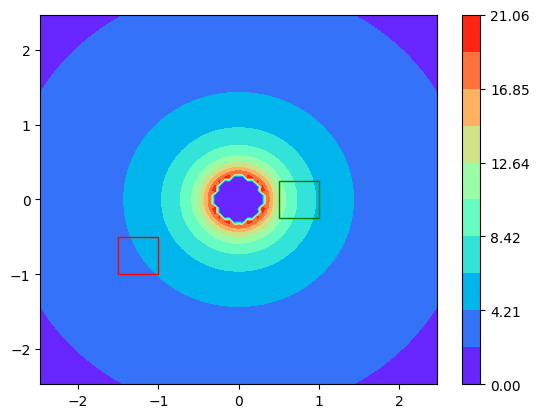

In [18]:
# Replot with ROI and OAR visualized
fig1, ax1 = plt.subplots()

contour1 = ax1.contourf(Xv, Yv, GAMMA_MAX, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar1 = fig1.colorbar(contour1)

# ROI is green
roi_box = patches.Rectangle((x_roi[0], y_roi[0]), x_roi[1] - x_roi[0], y_roi[1] - y_roi[0], fill=False, edgecolor="green")
ax1.add_patch(roi_box)

# OAR is red
oar_box = patches.Rectangle((x_oar[0], y_oar[0]), x_oar[1] - x_oar[0], y_oar[1] - y_oar[0], fill=False, edgecolor="red")
ax1.add_patch(oar_box)

Now that we have a proxy for voxel energy that does not require re-running a simulation at each optimization timestep, we have to connect this proxy to a formalism that allows us to actually perform the optimization. We'll do this using the mixed-integer linear programming (or MILP) model. This is a common method of optimizing over discrete variables and is helpfully provided in a SciPy package as `scipy.optimize.milp` (see https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.milp.html#scipy.optimize.milp).

We define the MILP model as follows. We are solving a problem of the form

$$\min_{\theta} \vec{c} \cdot \vec{\theta}$$

Such that the following conditions hold:

$$ \vec{l} \leq A \vec{\theta} \leq \vec{u} $$
$$ \theta_j \in \{ 0, 1 \} $$

In this case, the quantity $\vec{c} \cdot \vec{\theta}$ is our objective function, the vectors $\vec{l}$ and $\vec{u}$ are lower/upper bounds, and $A$ is a constraints matrix. Also note that we have constrainted the elements of $\vec{\theta}$ to be either 0 or 1.

Let's make the MILP model more relevant to our system. First we'll determine how to set the upper and lower bounds and then we'll define the objective function by setting a value for the quantity $\vec{c}$.

In [19]:
# Step 3 - compute gamma_ij for ith voxel, jth rod --> store in A matrix per model
# ROI
roi, roi_x_vox, roi_y_vox = select_region(x_roi, y_roi)
roi_voxels = np.shape(roi)[0]*np.shape(roi)[1]

# OAR
oar, oar_x_vox, oar_y_vox = select_region(x_oar, y_oar)
oar_voxels = np.shape(oar)[0]*np.shape(oar)[1]

gamma_storage = []

for i in range(np.shape(roi)[0]):
    for j in range(np.shape(roi)[1]):
        gamma_storage.append(compute_gamma(roi[i][j]))

for i in range(np.shape(oar)[0]):
    for j in range(np.shape(oar)[1]):
        gamma_storage.append(compute_gamma(oar[i][j]))

A = np.stack(gamma_storage)
print(np.shape(A))

(153, 6)


When thinking about upper and lower bounds, we first need to recognize the following fact: the maximum dose for any voxel occurs when all of the applicator's channels are open (that is, when $\vec{\theta} = [1, 1, ..., 1]^T$). This will be important later as it will allow us to connect the quantity $\Gamma_i$ to the physical dose a voxel would receive in the "real world."

For now, let's work with a toy system to get a sense of how the matrix $A$ will be physically relevant. Suppose we have a ROI with 2 voxels, an OAR with 2 voxels, and 3 total shielding channels available in our applicator. We're first going to compute the quantity $\gamma_{ij}$ for each voxel $i$ and each shielding channel $j$. Let $i = 1, 2$ denote the voxels in the ROI and $i = 3, 4$ denote the voxels in the OAR. Similarly, let's number our shielding channels $j = 1, 2, 3$. We can compute $4 \times 3 = 12$ total $\gamma_{ij}$ values and store them in a matrix:

$$ \begin{bmatrix}
\gamma_{11} & \gamma_{12} & \gamma_{13}\\
\gamma_{21} & \gamma_{22} & \gamma_{23}\\
\gamma_{31} & \gamma_{32} & \gamma_{33}\\
\gamma_{41} & \gamma_{42} & \gamma_{43}
\end{bmatrix} $$

In this matrix, note that the first two rows represent $\gamma$ values for the ROI (since $i = 1, 2$) and the second two rows represent $\gamma$ values for the OAR (since $i = 3, 4$). Similarly, the columns represent the different shielding channels from $j = 1$ to $j = 3$. Let's now multiply this matrix by the vector $\vec{\theta}$ representing the arrangement of our shielding rods:

$$ \begin{bmatrix}
\gamma_{11} & \gamma_{12} & \gamma_{13}\\
\gamma_{21} & \gamma_{22} & \gamma_{23}\\
\gamma_{31} & \gamma_{32} & \gamma_{33}\\
\gamma_{41} & \gamma_{42} & \gamma_{43}
\end{bmatrix} \begin{bmatrix}
\theta_{1}\\
\theta_{2}\\
\theta_{3}\\
\end{bmatrix} = \begin{bmatrix}
\gamma_{11}\theta_1 + \gamma_{12}\theta_2 + \gamma_{13}\theta_3\\
\gamma_{21}\theta_1 + \gamma_{22}\theta_2 + \gamma_{23}\theta_3\\
\gamma_{31}\theta_1 + \gamma_{32}\theta_2 + \gamma_{33}\theta_3\\
\gamma_{41}\theta_1 + \gamma_{42}\theta_2 + \gamma_{43}\theta_3
\end{bmatrix} = \begin{bmatrix}
\Gamma_{1}\\
\Gamma_{2}\\
\Gamma_{3}\\
\Gamma_{4}
\end{bmatrix}  $$

Notice that the result is simply a vector of the quantity $\Gamma_i$ for the $i$th voxel, with the first two elements representing the ROI and the second two elements representing the OAR. Let's rewrite this in a more compact form:

$$ A \vec{\theta} = \vec{\Gamma}$$

where each element of the matrix $A$ is given by $A_{ij} = \gamma_{ij}$ and $\vec{\Gamma} = [\Gamma_1, \Gamma_2, ..., \Gamma_n]^T$ for $n$ total voxels. Note that we define the matrix $A$ in the cell immediately above labeled `# Step 3 - compute gamma_ij for ith voxel, jth rod --> store in A matrix per model`.

Now that we've defined the matrix $A$, how do we set our upper and lower bounds? Recall that the maximum dose for any voxel occurs when every shielding channel is open. This corresponds to the quantity $\Gamma_{i}^{\text{max}} = \vec{\gamma}_i \cdot [1, 1, 1, 1, 1, 1]^T$ for the $i$th voxel. In other words, there is a direct correspondance between the maximum dose a voxel will receive in a Monte Carlo simulation and the value $\Gamma_{i}^{\text{max}}$ for that voxel in our MILP model. This allows us to express our upper and lower bounds in terms of a percentage of $\Gamma_{i}^{\text{max}}$ for voxels in our ROI or OAR.

An example of these upper/lower bounds might be the following:

$$ \forall i \in \text{ROI} \rightarrow 0.6 \cdot \Gamma_{i}^{\text{max}} \leq \Gamma_i \leq 0.9 \cdot \Gamma_{i}^{\text{max}} $$
$$ \forall i \in \text{OAR} \rightarrow 0 \leq \Gamma_i \leq 0.2 \cdot \Gamma_{i}^{\text{max}} $$

We read the first line as, "for all voxels in the ROI, we want the quantity $\Gamma_i$ (our proxy for dose) to be between 60% and 90% of the 'maximum dose' $\Gamma_{i}^{\text{max}}$ that occurs when all shielding channels are open." The second line similarly states that all voxels in the OAR should have a dose between 0% and 20% of the "maximum dose" $\Gamma_{i}^{\text{max}}$.

Let's connect this back to the matrix $A$ using our toy system above. We'll define $u_{\text{ROI}}$ and $l_{\text{ROI}}$ as the upper and lower bounds (expressed as a percentage) for the ROI, while $u_{\text{OAR}}$ will be the upper bound for the OAR. In order for the MILP algorithm to return non-trivial results, we always set $l_{\text{OAR}} = 0$. We can create an upper bound vector as follows:

$$ \vec{u} = \begin{bmatrix}
u_{\text{ROI}} \cdot \Gamma_{1}^{\text{max}}\\
u_{\text{ROI}} \cdot \Gamma_{2}^{\text{max}}\\
u_{\text{OAR}} \cdot \Gamma_{3}^{\text{max}}\\
u_{\text{OAR}} \cdot \Gamma_{3}^{\text{max}}\\
\end{bmatrix} $$

Again notice that the first two elements represent the ROI and the second two elements represent the OAR. The lower bound vector is given by:

$$ \vec{l} = \begin{bmatrix}
l_{\text{ROI}} \cdot \Gamma_{1}^{\text{max}}\\
l_{\text{ROI}} \cdot \Gamma_{2}^{\text{max}}\\
0\\
0\\
\end{bmatrix} $$

Note that the lower bound for the OAR voxels is 0 as we noted above. We can finally write our constrants as follows:

$$ \vec{l} \leq A \vec{\theta} \leq \vec{u} $$

Written out, this equation becomes the following:

$$ \begin{bmatrix}
l_{\text{ROI}} \cdot \Gamma_{1}^{\text{max}}\\
l_{\text{ROI}} \cdot \Gamma_{2}^{\text{max}}\\
0\\
0\\
\end{bmatrix} \leq \begin{bmatrix}
\Gamma_{1}\\
\Gamma_{2}\\
\Gamma_{3}\\
\Gamma_{4}
\end{bmatrix} \leq \begin{bmatrix}
u_{\text{ROI}} \cdot \Gamma_{1}^{\text{max}}\\
u_{\text{ROI}} \cdot \Gamma_{2}^{\text{max}}\\
u_{\text{OAR}} \cdot \Gamma_{3}^{\text{max}}\\
u_{\text{OAR}} \cdot \Gamma_{3}^{\text{max}}\\
\end{bmatrix} $$

Which is equivalent to the example upper/lower bounds we stated a bit earlier. Note that we can easily generalize this model to any number of voxels with any number of shielding channels, even if the shielding channels are spread across multiple different applicators in the same patient. The upper/lower bounds are defined in the cells below labeled `# Step 4` and `# Step 5`.

In [20]:
# Step 4 - define upper/lower bounds
u_roi = 0.9
l_roi = 0.15

u_oar = 0.3
l_oar = 0

In [21]:
# Step 5 - construct upper/lower bound vectors from GAMMA_MAX matrix
upper = []
lower = []
for i in np.arange(roi_x_vox[0], roi_x_vox[1]):
    for j in np.arange(roi_y_vox[0], roi_y_vox[1]):
        upper.append(u_roi*GAMMA_MAX[i][j])
        lower.append(l_roi*GAMMA_MAX[i][j])

for i in np.arange(oar_x_vox[0], oar_x_vox[1]):
    for j in np.arange(oar_y_vox[0], oar_y_vox[1]):
        upper.append(u_oar*GAMMA_MAX[i][j])
        lower.append(0)

upper = np.array(upper)
lower = np.array(lower)

### Run optimization

Now that we've constructed the upper/lower bounds for our constraint matrix $A$, we can construct the actual objective function $f$ for our model. The basic structure of this function is defined via the MILP model:

$$f(\vec{\theta}) = \vec{c} \cdot \vec{\theta}$$

In this case, we need a definition for the coefficient vector $\vec{c}$. While there are many ways we could construct this coefficient, for now we're going to keep it simple and define $\vec{c}$ as follows:

$$ \vec{c} \equiv a \sum_{i \in \text{ROI}} \vec{\gamma_i} - b \sum_{k \in \text{OAR}} \vec{\gamma_k} $$

That is, we sum $\vec{\gamma_i}$ for all voxels in the ROI and OAR and take the difference of these quantities. The coefficients $a$ and $b$ are real numbers that can be adjusted to alter the optimization results. Thus, our full objective function is defined as follows:

$$ f(\vec{\theta}) = \left( a \sum_{i \in \text{ROI}} \vec{\gamma_i} - b \sum_{k \in \text{OAR}} \vec{\gamma_k} \right) \cdot \vec{\theta} = a \sum_{i \in \text{ROI}} \vec{\gamma_i} \cdot \vec{\theta} - b \sum_{k \in \text{OAR}} \vec{\gamma_k} \cdot \vec{\theta} $$

Let's take a moment to understand why this is a logical initial objective function. Per our definitions above, note that $\Gamma_i = \vec{\gamma}_i 
\cdot \vec{\theta}$, so we can rewrite this as:

$$ f(\vec{\theta}) = a \sum_{i \in \text{ROI}} \Gamma_i - b \sum_{k \in \text{OAR}} \Gamma_k $$

Recall that we intepret $\Gamma$ as the "dose" a voxel receives in this formalism. Thus, this objective function is taking the difference of the "dose" in the ROI and the "dose" in the OAR. Maximizing $f(\vec{\theta})$ corresponds to making the dose at the ROI as large as possible while making the dose at the OAR as small as possible, exactly what we desire from our optimization. Note that since the SciPy MILP model is only able to minimize functions, we set $a = b = -1$ to ensure that minimizing $f(\vec{\theta})$ still makes the dose at the ROI large.

The cells below construct the objective function and run the SciPy MILP model to optimize the rod arrangement for an ROI that is between rods #2 and #3 (at the 3 o'clock position) and an OAR roughly in the bottom-left corner of the plot. These parameters are included in a cell above labeled `# Step 2 - define ROI and OAR`.

In [22]:
# Construct objective function coefficients c
gamma_roi = np.zeros(NUM_RODS)
for i in range(np.shape(roi)[0]):
    for j in range(np.shape(roi)[1]):
        gamma_roi += compute_gamma(roi[i][j])

gamma_oar = np.zeros(NUM_RODS)
for i in range(np.shape(oar)[0]):
    for j in range(np.shape(oar)[1]):
        gamma_oar += compute_gamma(oar[i][j])

c = gamma_roi - gamma_oar

In [23]:
# Apply decision variable constraints
bounds = optimize.Bounds(0, 1)
integrality = np.full_like(c, True)

In [24]:
# Run optimization
constraints = optimize.LinearConstraint(A=A, lb=lower, ub=upper)
solution = optimize.milp(-c, constraints=constraints, integrality=integrality, bounds=bounds)

In [25]:
print(solution.status)
print(solution.x)

0
[0. 1. 0. 0. 0. 0.]


The optimization model has returned an optimal value $\vec{\theta} = [0, 1, 0, 0, 0, 0]^T$ corresponding to rod #2 removed and all other rods inserted. This solution makes intuitive sense: the presence of an OAR in the bottom-left corner of the plot means that other rods we may have opened to irradiate the ROI (for example, rod #3 at the 4 o'clock position) would provide too much dose to the OAR. Of note, the optimization is highly sensitive to the upper and lower bounds we defined earlier in our model. I'm currently working on understanding how varying these bounds changes the performance of the model! Another next step is to run this model with multiple applicators and multiple OARs to determine how it performs in more complex scenarios.

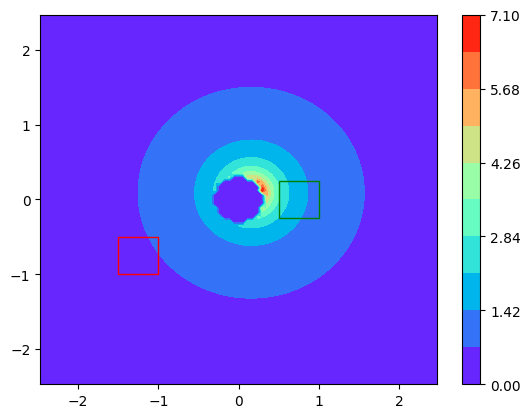

In [28]:
# Replot solution with ROI and OAR shown
# Recompute gamma values with new rod configuration given by the parameter solution.x
GAMMA_SOL = np.empty((bins_mosh, bins_mosh))

for i in range(bins_mosh):
    for j in range(bins_mosh):
        if np.linalg.norm((Xv[i][j], Yv[i][j])) <= applicator_rad:
            GAMMA_SOL[i][j] = 0
        else:
            g = compute_gamma(np.array([Xv[i][j], Yv[i][j]]))
            GAMMA_SOL[i][j] = np.dot(g, solution.x)

fig2, ax2 = plt.subplots()

contour2 = ax2.contourf(Xv, Yv, GAMMA_SOL, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar2 = fig2.colorbar(contour2)

# ROI is green
roi_box = patches.Rectangle((x_roi[0], y_roi[0]), x_roi[1] - x_roi[0], y_roi[1] - y_roi[0], fill=False, edgecolor="green")
ax2.add_patch(roi_box)

# OAR is red
oar_box = patches.Rectangle((x_oar[0], y_oar[0]), x_oar[1] - x_oar[0], y_oar[1] - y_oar[0], fill=False, edgecolor="red")
ax2.add_patch(oar_box)